 # Exploration NDVI — Détection de la désertification au Niger Ce notebook explore l'évolution du NDVI (2000-2025) pour Diffa, Tillabéri et Zinder, calcule une tendance spatiale par pixel, et quantifie les surfaces de sol nu / végétation clairsemée / végétation dense entre 2016 et 2025.
 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

zones = ["diffa", "tillaberi", "zinder"]
data = {}

for zone in zones:
    df = pd.read_csv(f"../data/ndvi_{zone}.csv", parse_dates=["date"])
    data[zone] = df
    print(f"{zone}: {len(df)} lignes, {df['ndvi_mean'].isna().sum()} valeurs manquantes")

data["diffa"].head()

diffa: 120 lignes, 9 valeurs manquantes
tillaberi: 120 lignes, 5 valeurs manquantes
zinder: 120 lignes, 3 valeurs manquantes


,date,ndvi_mean,n_images
0,2016-01-01,0.171220,4
1,2016-02-01,0.153239,4
2,2016-03-01,NaN,0
3,2016-04-01,0.145945,8
4,2016-05-01,0.123627,4


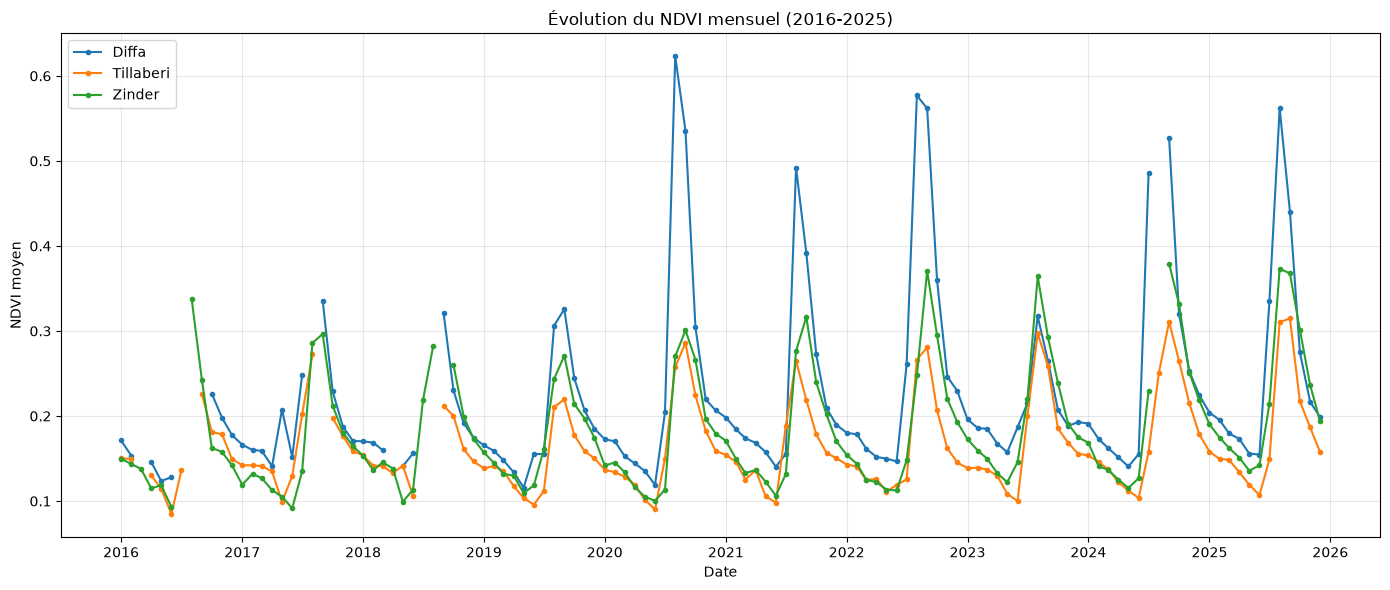

In [2]:
fig, ax = plt.subplots(figsize=(14, 6))

for zone in zones:
    df = data[zone]
    ax.plot(df["date"], df["ndvi_mean"], marker="o", markersize=3, label=zone.capitalize())

ax.set_title("Évolution du NDVI mensuel (2016-2025)")
ax.set_xlabel("Date")
ax.set_ylabel("NDVI moyen")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../outputs/ndvi_evolution_2016_2025.png", dpi=150)
plt.show()

Diffa: pente = +0.0301 NDVI/an (hausse)
Tillaberi: pente = +0.0100 NDVI/an (hausse)
Zinder: pente = +0.0098 NDVI/an (hausse)


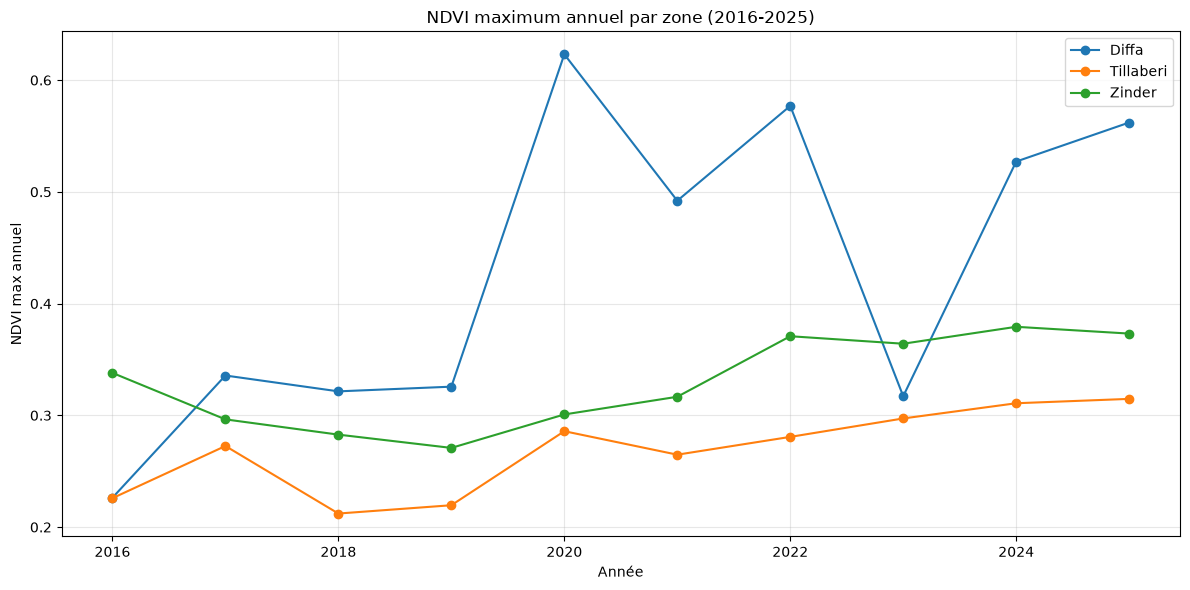

In [3]:
fig, ax = plt.subplots(figsize=(12, 6))

annual_max = {}
for zone in zones:
    df = data[zone].copy()
    df["year"] = df["date"].dt.year
    yearly = df.groupby("year")["ndvi_mean"].max()
    annual_max[zone] = yearly
    ax.plot(yearly.index, yearly.values, marker="o", label=zone.capitalize())

    # Tendance linéaire (régression simple) pour visualiser la pente sur 10 ans
    import numpy as np
    coeffs = np.polyfit(yearly.index, yearly.values, 1)
    trend = np.poly1d(coeffs)
    print(f"{zone.capitalize()}: pente = {coeffs[0]:+.4f} NDVI/an "
          f"({'baisse' if coeffs[0] < 0 else 'hausse'})")

ax.set_title("NDVI maximum annuel par zone (2016-2025)")
ax.set_xlabel("Année")
ax.set_ylabel("NDVI max annuel")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../outputs/ndvi_max_annuel_2016_2025.png", dpi=150)
plt.show()

In [4]:
import ee
ee.Initialize(project="desertification-niger")

ZONES = {
    "Diffa": ee.Geometry.Rectangle([12.8, 13.0, 13.5, 13.6]),
    "Tillaberi": ee.Geometry.Rectangle([0.9, 14.0, 1.6, 14.6]),
    "Zinder": ee.Geometry.Rectangle([8.7, 13.5, 9.4, 14.1]),
}

def mask_clouds_s2(image):
    scl = image.select("SCL")
    mask = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
    return image.updateMask(mask)

def add_ndvi(image):
    ndvi = image.normalizedDifference(["B8", "B4"]).rename("NDVI")
    return image.addBands(ndvi)

In [5]:
#Cellule suivante — fonction de calcul de tendance :
def compute_trend(zone_geom, start_year=2016, end_year=2025):
    collection = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(zone_geom)
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 40))
        .map(mask_clouds_s2)
        .map(add_ndvi)
    )

    def annual_image(year):
        year = ee.Number(year)
        start = ee.Date.fromYMD(year, 1, 1)
        end = ee.Date.fromYMD(year, 12, 31)
        ndvi_max = collection.filterDate(start, end).select("NDVI").max()
        #return ndvi_max.addBands(ee.Image.constant(year).rename("year")).set("year", year)
        return ndvi_max.addBands(ee.Image.constant(year).rename("year").float()).set("year", year)

    years = ee.List.sequence(start_year, end_year)
    annual_imgs = ee.ImageCollection(years.map(annual_image))

    trend = annual_imgs.select(["year", "NDVI"]).reduce(ee.Reducer.linearFit())
    return trend.select("scale").clip(zone_geom)

In [6]:
#Carte de tendance pour Diffa
from IPython.display import Image, display

zone_name = "Diffa"
slope_img = compute_trend(ZONES[zone_name])

vis_params = {
    "min": -0.05, "max": 0.05,
    "palette": ["d73027", "fee08b", "1a9850"],
}

url = slope_img.getThumbURL({**vis_params, "region": ZONES[zone_name], "dimensions": 600})
display(Image(url=url))

In [7]:
print(url)

https://earthengine.googleapis.com/v1/projects/desertification-niger/thumbnails/56234708c8ffea16ebf14a740b888647-40eb638dfe3b324dd0becb1fb43faaf9:getPixels


In [8]:
dem = ee.Image("USGS/SRTMGL1_003")

for zone in zones:
    zone_name = zone.capitalize()
    stats = dem.reduceRegion(
        reducer=ee.Reducer.minMax().combine(ee.Reducer.mean(), sharedInputs=True),
        geometry=ZONES[zone_name],
        scale=90,
        maxPixels=1e9,
    ).getInfo()
    print(f"{zone_name}: altitude min={stats['elevation_min']}m, "
          f"max={stats['elevation_max']}m, moyenne={stats['elevation_mean']:.1f}m")

Diffa: altitude min=267m, max=317m, moyenne=295.5m
Tillaberi: altitude min=188m, max=334m, moyenne=243.8m
Zinder: altitude min=375m, max=655m, moyenne=451.3m


In [9]:
dem = ee.Image("USGS/SRTMGL1_003")
zones = ["diffa", "tillaberi", "zinder"]

for zone in zones:
    zone_name = zone.capitalize()
    stats = dem.reduceRegion(
        reducer=ee.Reducer.minMax().combine(ee.Reducer.mean(), sharedInputs=True),
        geometry=ZONES[zone_name],
        scale=90,
        maxPixels=1e9,
    ).getInfo()
    print(f"{zone_name}: altitude min={stats['elevation_min']}m, "
          f"max={stats['elevation_max']}m, moyenne={stats['elevation_mean']:.1f}m")

Diffa: altitude min=267m, max=317m, moyenne=295.5m
Tillaberi: altitude min=188m, max=334m, moyenne=243.8m
Zinder: altitude min=375m, max=655m, moyenne=451.3m


In [10]:
def mask_clouds_landsat(image):
    qa = image.select("QA_PIXEL")
    cloud_bit = 1 << 3
    shadow_bit = 1 << 4
    mask = qa.bitwiseAnd(cloud_bit).eq(0).And(qa.bitwiseAnd(shadow_bit).eq(0))
    return image.updateMask(mask)

def scale_landsat_sr(image):
    optical = image.select("SR_B.").multiply(0.0000275).add(-0.2)
    return image.addBands(optical, None, True)

def add_ndvi_l57(image):  # Landsat 5 & 7 : rouge=SR_B3, PIR=SR_B4
    ndvi = image.normalizedDifference(["SR_B4", "SR_B3"]).rename("NDVI")
    return image.addBands(ndvi)

def add_ndvi_l89(image):  # Landsat 8 & 9 : rouge=SR_B4, PIR=SR_B5
    ndvi = image.normalizedDifference(["SR_B5", "SR_B4"]).rename("NDVI")
    return image.addBands(ndvi)

def get_landsat_collection(zone_geom, start, end):
    l5 = (ee.ImageCollection("LANDSAT/LT05/C02/T1_L2")
          .filterBounds(zone_geom).filterDate(start, end)
          .map(mask_clouds_landsat).map(scale_landsat_sr).map(add_ndvi_l57))
    l7 = (ee.ImageCollection("LANDSAT/LE07/C02/T1_L2")
          .filterBounds(zone_geom).filterDate(start, end)
          .map(mask_clouds_landsat).map(scale_landsat_sr).map(add_ndvi_l57))
    l8 = (ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
          .filterBounds(zone_geom).filterDate(start, end)
          .map(mask_clouds_landsat).map(scale_landsat_sr).map(add_ndvi_l89))
    return l5.merge(l7).merge(l8)

In [11]:
landsat_annual_max = {}

for zone in zones:
    zone_name = zone.capitalize()
    coll = get_landsat_collection(ZONES[zone_name], "2000-01-01", "2015-12-31")
    records = []
    for year in range(2000, 2016):
        yearly = coll.filterDate(f"{year}-01-01", f"{year}-12-31").select("NDVI").max()
        stats = yearly.reduceRegion(
            reducer=ee.Reducer.mean(), geometry=ZONES[zone_name], scale=30, maxPixels=1e9
        )
        val = stats.get("NDVI").getInfo()
        records.append({"year": year, "ndvi_max": val})
        print(f"{zone_name} {year}: {val}")
    landsat_annual_max[zone] = pd.DataFrame(records)
    landsat_annual_max[zone].to_csv(f"../data/ndvi_landsat_annual_{zone}.csv", index=False)

Diffa 2000: 0.3111582430134514
Diffa 2001: 0.2567194945394144
Diffa 2002: 0.32452049204752426
Diffa 2003: 0.313354731520007
Diffa 2004: 0.28534403783815054
Diffa 2005: 0.32701451520386543
Diffa 2006: 0.21317143322549426
Diffa 2007: 0.37149170431175094
Diffa 2008: 0.3303674804750205
Diffa 2009: 0.34665435267554195
Diffa 2010: 0.28824666036415436
Diffa 2011: 0.2483801140428539
Diffa 2012: 0.37531231187172365
Diffa 2013: 0.5968897293508558
Diffa 2014: 0.5315425708129053
Diffa 2015: 0.5021854970973105
Tillaberi 2000: 0.240566482467022
Tillaberi 2001: 0.2524620788930819
Tillaberi 2002: 0.220015456958751
Tillaberi 2003: 0.17016772382030085
Tillaberi 2004: 0.1909430693154217
Tillaberi 2005: 0.1827063896713836
Tillaberi 2006: 0.1937417469286476
Tillaberi 2007: 0.2970615235264974
Tillaberi 2008: 0.20230401628142625
Tillaberi 2009: 0.21687319482444184
Tillaberi 2010: 0.18895292819427975
Tillaberi 2011: 0.1520107419875753
Tillaberi 2012: 0.2023558169490396
Tillaberi 2013: 0.2668775080223449
Tilla

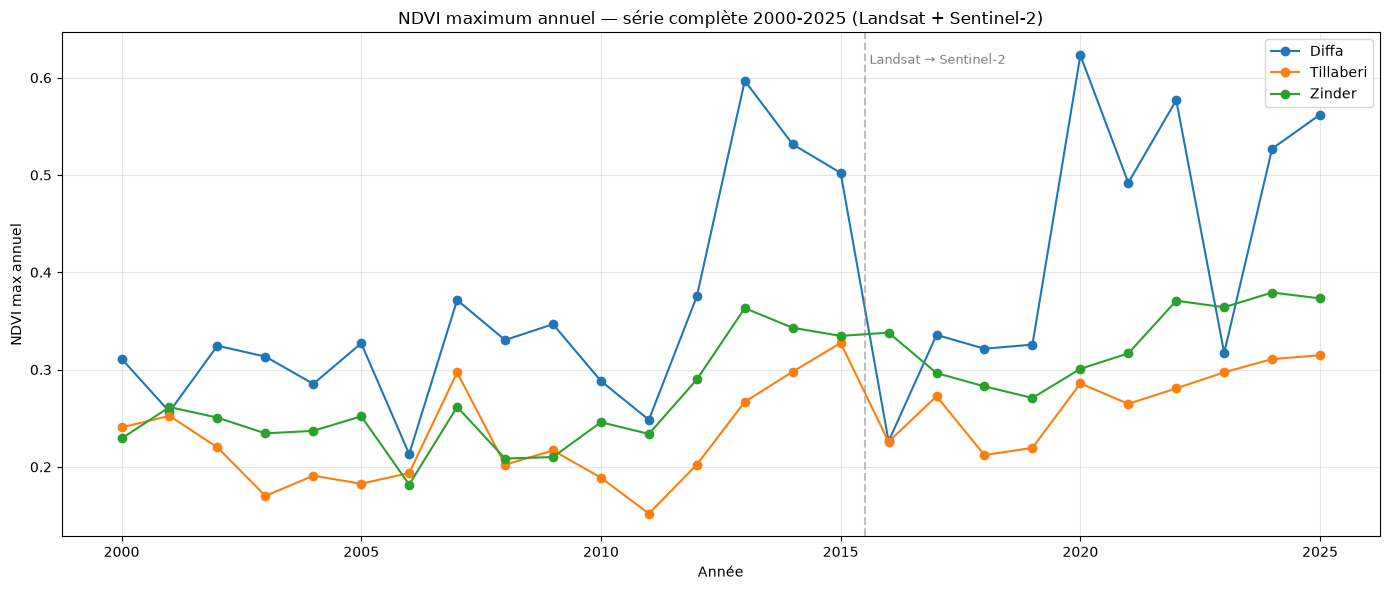

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 6))

full_series = {}
for zone in zones:
    # Série Landsat (2000-2015)
    landsat_df = landsat_annual_max[zone].rename(columns={"ndvi_max": "ndvi"})

    # Série Sentinel-2 : NDVI max par an, à partir des données mensuelles déjà chargées
    s2_df = data[zone].copy()
    s2_df["year"] = s2_df["date"].dt.year
    s2_annual = s2_df.groupby("year")["ndvi_mean"].max().reset_index()
    s2_annual = s2_annual.rename(columns={"ndvi_mean": "ndvi"})

    combined = pd.concat([landsat_df, s2_annual], ignore_index=True).sort_values("year")
    combined["source"] = combined["year"].apply(lambda y: "Landsat" if y <= 2015 else "Sentinel-2")
    full_series[zone] = combined
    combined.to_csv(f"../data/ndvi_full_series_{zone}.csv", index=False)

    ax.plot(combined["year"], combined["ndvi"], marker="o", label=zone.capitalize())

ax.axvline(2015.5, color="gray", linestyle="--", alpha=0.5)
ax.text(2015.6, ax.get_ylim()[1]*0.95, "Landsat → Sentinel-2", fontsize=9, color="gray")
ax.set_title("NDVI maximum annuel — série complète 2000-2025 (Landsat + Sentinel-2)")
ax.set_xlabel("Année")
ax.set_ylabel("NDVI max annuel")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../outputs/ndvi_full_series_2000_2025.png", dpi=150)
plt.show()

In [13]:
for zone_name in ["Tillaberi", "Zinder"]:
    print(f"Calcul de la tendance pour {zone_name}...")
    slope_img = compute_trend(ZONES[zone_name])

    vis_params = {
        "min": -0.05, "max": 0.05,
        "palette": ["d73027", "fee08b", "1a9850"],
    }

    url = slope_img.getThumbURL({**vis_params, "region": ZONES[zone_name], "dimensions": 600})
    print(f"URL {zone_name}: {url}")
    display(Image(url=url))

Calcul de la tendance pour Tillaberi...
URL Tillaberi: https://earthengine.googleapis.com/v1/projects/desertification-niger/thumbnails/d40392b3af79cc1d404e702c95447e04-a86ccf00e1d9bb302ede03c4a6cfd819:getPixels


Calcul de la tendance pour Zinder...
URL Zinder: https://earthengine.googleapis.com/v1/projects/desertification-niger/thumbnails/32b1fffd5d2e338450407823b6cb5067-c7444b36d14f6ca4e8be9956842cb404:getPixels


In [ ]:
def get_ndvi_composite(zone_geom, year):
    """NDVI médian sur l'année (composite annuel, réduit le bruit)."""
    collection = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(zone_geom)
        .filterDate(f"{year}-01-01", f"{year}-12-31")
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 40))
        .map(mask_clouds_s2)
        .map(add_ndvi)
    )
    return collection.select("NDVI").median().clip(zone_geom)

def classify_ndvi(ndvi_img):
    """0 = sol nu, 1 = végétation clairsemée, 2 = végétation dense."""
    bare = ndvi_img.lt(0.15)
    sparse = ndvi_img.gte(0.15).And(ndvi_img.lt(0.30))
    dense = ndvi_img.gte(0.30)
    return bare.multiply(0).add(sparse.multiply(1)).add(dense.multiply(2)).rename("classe")

def compute_class_areas_km2(classified_img, zone_geom, scale=30):
    """Retourne un dict {classe: surface_km2}."""
    pixel_area = ee.Image.pixelArea().divide(1e6)  # m² -> km²
    areas = {}
    for cls, name in [(0, "sol_nu"), (1, "veg_clairsemee"), (2, "veg_dense")]:
        mask = classified_img.eq(cls)
        area_img = pixel_area.updateMask(mask)
       # stats = area_img.reduceRegion(
           # reducer=ee.Reducer.sum(), geometry=zone_geom, scale=scale, maxPixels=1e9
       # )
        stats = area_img.reduceRegion(
    reducer=ee.Reducer.sum(), geometry=zone_geom, scale=scale, maxPixels=1e9, tileScale=4
)
        areas[name] = stats.get("area").getInfo()
    return areas

In [ ]:
results = []

for zone in zones:
    zone_name = zone.capitalize()
    print(f"Traitement {zone_name}...")

    for year in [2016, 2025]:
        ndvi_img = get_ndvi_composite(ZONES[zone_name], year)
        classified = classify_ndvi(ndvi_img)
        
        areas = compute_class_areas_km2(classified, ZONES[zone_name])
        areas["zone"] = zone_name
        areas["year"] = year
        results.append(areas)
        print(f"  {year}: sol_nu={areas['sol_nu']:.1f} km², "
              f"clairsemee={areas['veg_clairsemee']:.1f} km², "
              f"dense={areas['veg_dense']:.1f} km²")

df_areas = pd.DataFrame(results)
df_areas.to_csv("../data/classification_areas_2016_2025.csv", index=False)
df_areas

Traitement Diffa...
  2016: sol_nu=2204.2 km², clairsemee=2625.6 km², dense=204.9 km²
  2025: sol_nu=878.8 km², clairsemee=3593.6 km², dense=562.3 km²
Traitement Tillaberi...
  2016: sol_nu=2225.3 km², clairsemee=2594.0 km², dense=194.4 km²
  2025: sol_nu=2201.8 km², clairsemee=2603.4 km², dense=208.5 km²
Traitement Zinder...
  2016: sol_nu=3245.8 km², clairsemee=1750.4 km², dense=28.2 km²


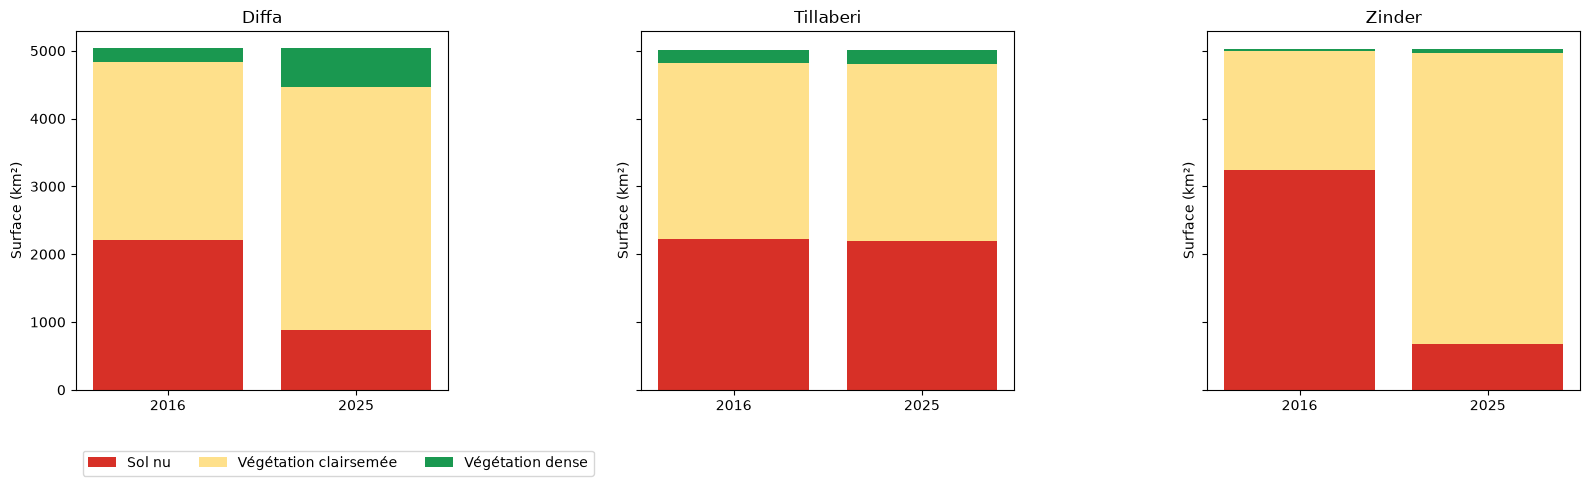

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, zone_name in zip(axes, ["Diffa", "Tillaberi", "Zinder"]):
    sub = df_areas[df_areas["zone"] == zone_name]
    x = ["2016", "2025"]
    bottom = [0, 0]
    for cls, color, label in [("sol_nu", "#d73027", "Sol nu"),
                                ("veg_clairsemee", "#fee08b", "Végétation clairsemée"),
                                ("veg_dense", "#1a9850", "Végétation dense")]:
        vals = sub[cls].values
        ax.bar(x, vals, bottom=bottom, color=color, label=label if zone_name == "Diffa" else "")
        bottom = [b + v for b, v in zip(bottom, vals)]
    ax.set_title(zone_name)
    ax.set_ylabel("Surface (km²)")

axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.15), ncol=3)
plt.tight_layout()
plt.savefig("../outputs/classification_comparaison_2016_2025.png", dpi=150, bbox_inches="tight")
plt.show()